# 정수기 불편 발생 후 유지·전환 판단 지원 — 보완 분석

분석 기준일: 2026-10-08. 분석 목적은 만들어 둔 기능을 정당화하는 것이 아니라, 공개 자료가 뒷받침하는 문제·판단 과제·지원 범위와 아직 검증하지 못한 고객 효과를 구분하는 것이다.

서로 다른 자료의 모집단을 합치지 않는다. 2025년 피해구제는 대표 고객 설문이 아니며, 표준답변은 문의 빈도가 아니다. 2019년 자료는 현재 발생률이나 장기 추세를 주장하는 용도로 사용하지 않는다. LG 혜택은 고객 수요·유지율의 통계가 아니다.

In [1]:
from pathlib import Path
import pandas as pd, re
from pypdf import PdfReader
from IPython.display import display, Image
ROOT = Path.cwd()
while not (ROOT / '핵심프로젝트.md').exists():
    if ROOT == ROOT.parent: raise FileNotFoundError('프로젝트 루트가 필요합니다.')
    ROOT = ROOT.parent
OUT = ROOT / '01_제출용/01_데이터분석/가공결과/유지전환'
OUT.mkdir(parents=True,exist_ok=True)
GRAPH = ROOT / '01_제출용/01_데이터분석/그래프'
GRAPH.mkdir(exist_ok=True)
source = ROOT / '01_제출용/01_데이터분석/자료/원본/표준답변/소비자상담_표준답변_20250725.csv'
qa_all = pd.read_csv(source, encoding='cp949', dtype=str).fillna('')
qa_all = qa_all.map(lambda x: x.strip() if isinstance(x,str) else x)
qa = qa_all[qa_all['품목명'].eq('정수기대여')].copy()
qa['번호'] = qa['번호'].astype(int)
qa['질문키'] = qa['질문'].str.replace(r'\s+', '', regex=True)
assert len(qa_all)==1332 and len(qa)==43 and qa['질문키'].nunique()==31
assert not qa[['번호','질문','답변','구분']].eq('').any().any()
print('전체 문서',len(qa_all),'정수기대여 문서',len(qa),'공백 제거 고유 질문',qa['질문키'].nunique())
print('대체 결측 없음; 계약 조건이 다른 유사 질문을 임의 삭제하지 않음.')

전체 문서 1332 정수기대여 문서 43 공백 제거 고유 질문 31
대체 결측 없음; 계약 조건이 다른 유사 질문을 임의 삭제하지 않음.


## 1. 표준답변 내용 재분류

원본 `구분`은 유지하고 질문의 촉발 상황을 추가 코딩한다. 하나의 고객 질문이 품질·계약·요금 범주에 중복 기재되는 점을 확인한다. 내용이 비슷해도 요구 결과가 다르면 구분하고, 그룹 번호는 해석용 분류이며 실제 사례 수를 뜻하지 않는다.

고객의 해지 표현, 타인이 권유한 신제품 설치, 이미 완료된 제품 교환을 분리한다. `필터 교체`를 `제품 재구독 의사`로 계산하지 않는다. 답변의 법률·요율은 현행 LG 계약에 적용하지 않는다.

In [2]:
groups = {
'변심·청약철회':[970,983], '개인 사정 중도해지·비용':[971,972,973,974,997,998,999,1000],
'해지 후 회수 지연':[975,987,1001], '광고와 관리 제공 조건 불일치':[976,1010],
'관리 방문 미이행 후 해지':[977,988], 'AS 지연':[978,989,1004], '이물질·수질 이상':[979,1011],
'이사 후 관리 불가':[980,991], '설치 환경 부적합·신제품 권유':[981,992], '해외 이주':[982,993],
'누수·재산 피해':[984,1005], '기기 하자 후 해지·요금':[985,994,1006],
'반복 하자 후 제품 교환·요금':[986,995,1007], '관리 미제공·요금':[990,1002],
'사용자 과실·수리비':[996,1008], '경제 사정·미납금':[1003], '수질·건강 피해':[1009,1012]}
map_group={i:g for g,ids in groups.items() for i in ids}
assert set(map_group)==set(qa['번호'])
qa['촉발상황']=qa['번호'].map(map_group)
qa['해지_언급']=qa['질문'].str.contains('해지|해제|청약철회',regex=True)
qa['타인_신제품권유']=qa['번호'].isin([981,992])
qa['제품교환_완료']=qa['번호'].isin([986,995,1007])
qa['고객_혜택목적_재구독의사_직접확인']=False # 질문 원문 검토: 명시 사례 없음
qa['관리_AS_품질_촉발']=qa['번호'].isin([977,978,979,984,985,986,988,989,990,994,995,996,1002,1004,1005,1006,1007,1008,1009,1011,1012])
qa['판단에_필요한_정보']=qa['촉발상황'].map(lambda g: '관리 약정·요청/방문 이력·계약·청구 조건' if ('관리' in g or 'AS' in g) else '증상·점검 기록·계약·청구 조건' if ('하자' in g or '누수' in g or '수질' in g or '이물' in g or '과실' in g) else '기존 계약기간·해지/이전 조건·신규 계약 변동 여부')
qa['Agent_지원']=qa['촉발상황'].map(lambda g: '안전/증빙 확인 후 상담 준비; 책임·면제·치료비 확정 금지' if ('건강' in g or '누수' in g or '수질' in g or '이물' in g) else '불편/약정 확인 → 유지 대안 → 고객 요청 시 기간·비용 확인')
cols=['번호','구분','질문','촉발상황','해지_언급','타인_신제품권유','제품교환_완료','고객_혜택목적_재구독의사_직접확인','관리_AS_품질_촉발','판단에_필요한_정보','Agent_지원']
qa[cols].to_csv(OUT/'표준답변_43행_내용분류.csv',index=False,encoding='utf-8-sig')
unique = qa.drop_duplicates('질문키')
summary=qa.groupby('촉발상황').agg(문서행수=('번호','size'),고유질문수=('질문키','nunique')).sort_values('문서행수',ascending=False)
summary.to_csv(OUT/'표준답변_분류집계.csv',encoding='utf-8-sig')
display(summary)
print('해지 언급 문서/고유 질문:',qa['해지_언급'].sum(),unique['해지_언급'].sum())
print('관리·AS·품질 촉발과 해지 표현이 함께 있는 문서/고유 질문:',(qa['관리_AS_품질_촉발'] & qa['해지_언급']).sum(),(unique['관리_AS_품질_촉발'] & unique['해지_언급']).sum())
print('타인 신제품 권유 문서',qa['타인_신제품권유'].sum(),'제품교환 완료 문서',qa['제품교환_완료'].sum(),'고객 혜택목적 재구독 직접 표현',qa['고객_혜택목적_재구독의사_직접확인'].sum())

,문서행수,고유질문수
촉발상황,,
개인 사정 중도해지·비용,8,4
AS 지연,3,3
기기 하자 후 해지·요금,3,3
반복 하자 후 제품 교환·요금,3,1
해지 후 회수 지연,3,1
관리 방문 미이행 후 해지,2,2
광고와 관리 제공 조건 불일치,2,2
관리 미제공·요금,2,2
누수·재산 피해,2,1


해지 언급 문서/고유 질문: 31 21
관리·AS·품질 촉발과 해지 표현이 함께 있는 문서/고유 질문: 13 9
타인 신제품 권유 문서 2 제품교환 완료 문서 3 고객 혜택목적 재구독 직접 표현 0


## 2. 2025년 KCA 피해구제 재검산과 기존 보고서에서 빠진 근거

원문 3쪽: 사유와 연령. 4쪽: 계약 세부 분류 및 159건의 기간 확인 가능 부분집합. 5쪽: 관리 미이행으로 해지를 요구한 사례. 6쪽: 제품 교체 시 기존 계약 유지·변경 확인 안내.

아래 수치는 원문 표를 수작업 전사한 뒤 합계·분모·문구 존재를 검산한다. OCR/원본 사건 전체를 자동 분석한 결과가 아니다. 471건의 원문 표기 비율 32.1%는 건수 재계산 32.2%와 달라 둘을 구분한다.

In [3]:
pdf=ROOT/'01_제출용/01_데이터분석/자료/원본/피해예방/KCA_정수기렌탈_피해예방주의보_20250530.pdf'
pages=[page.extract_text() or '' for page in PdfReader(pdf).pages]
flat=lambda s: re.sub(r'\s+','',s)
assert '277' in pages[3] and '471' in pages[2]
assert '세차례관리가이행되지' in flat(pages[4])
assert '기존계약의유지또는변경여부' in flat(pages[5])
reasons=pd.DataFrame({'사유':['계약','품질·AS','부당행위','가격·요금','안전','표시·약관','기타'], '건수':[823,471,96,21,19,17,15], '원문비율':[56.3,32.1,6.6,1.4,1.3,1.2,1.1]})
assert reasons['건수'].sum()==1462
reasons['건수재계산비율']=(reasons['건수']/1462*100).round(1)
reasons.to_csv(OUT/'KCA2025_사유별_검산.csv',index=False,encoding='utf-8-sig')
contract=pd.DataFrame({'계약세부':['해지·위약금','계약불이행','기타'],'건수':[503,277,43]})
assert contract['건수'].sum()==823
contract['계약823건내비율']=(contract['건수']/823*100).round(1)
contract['전체1462건내비율']=(contract['건수']/1462*100).round(1)
contract.to_csv(OUT/'KCA2025_계약세부_검산.csv',index=False,encoding='utf-8-sig')
age=pd.DataFrame({'연령':['10대','20대','30대','40대','50대','60대','70대','80대 이상'],'건수':[1,55,302,500,339,162,54,28]})
assert age['건수'].sum()==1441
age['확인1441건내비율']=(age['건수']/1441*100).round(1)
age.to_csv(OUT/'KCA2025_연령별_검산.csv',index=False,encoding='utf-8-sig')
display(reasons);display(contract);display(age)
print('연령 미확인',1462-1441,'건. 30~50대 비중',round(1141/1441*100,1),'% — 피해구제 연령 확인 집단이며 전체 LG 고객 비중 아님.')
print('관리 미이행 사례와 제품 교체 시 계약 변동 확인 안내를 원문 5·6쪽에서 확인.')

,사유,건수,원문비율,건수재계산비율
0,계약,823,56.3,56.3
1,품질·AS,471,32.1,32.2
2,부당행위,96,6.6,6.6
3,가격·요금,21,1.4,1.4
4,안전,19,1.3,1.3
5,표시·약관,17,1.2,1.2
6,기타,15,1.1,1.0


,계약세부,건수,계약823건내비율,전체1462건내비율
0,해지·위약금,503,61.1,34.4
1,계약불이행,277,33.7,18.9
2,기타,43,5.2,2.9


,연령,건수,확인1441건내비율
0,10대,1,0.1
1,20대,55,3.8
2,30대,302,21.0
3,40대,500,34.7
4,50대,339,23.5
5,60대,162,11.2
6,70대,54,3.7
7,80대 이상,28,1.9


연령 미확인 21 건. 30~50대 비중 79.2 % — 피해구제 연령 확인 집단이며 전체 LG 고객 비중 아님.
관리 미이행 사례와 제품 교체 시 계약 변동 확인 안내를 원문 5·6쪽에서 확인.


## 3. 추가 공식 자료와 적용 한계

2019 KCA 원문은 관리 불만으로 해지를 요구할 때 추가 비용 분쟁이 발생한다는 연결을 서술한다. 과거 자료는 현재 관리 피해 비중 또는 2025년 자료와의 증가율로 연결하지 않는다. 원문 HTML 직접 수집은 인증서 오류로 실패하여 웹 도구로 확인한 공식 본문 발췌·출처를 별도 보관한다.

LG 10월 교체보상은 ‘LG 내 전환 대안이 실제 제시된다’는 사업적 맥락이다. 실제 고객의 혜택 선호, 교체 의도, 유지율 개선을 측정하지 못한다. 본 분석은 신규 기간·설치 조건이 확인되지 않은 고객에게 혜택을 확정하지 않는다.

In [4]:
historical=pd.DataFrame({'유형':['계약','제품 품질','관리서비스','설치','렌탈료','원문 미열거 잔여(검산)'],'건수':[221,217,152,102,75,7]})
assert historical['건수'].sum()==774 and 951-177==774
historical['774건내비율']=(historical['건수']/774*100).round(1)
historical.to_csv(OUT/'KCA2019_별도모집단_검산.csv',index=False,encoding='utf-8-sig')
display(historical)
benefit_text=(ROOT/'01_제출용/01_데이터분석/자료/원본/유지전환_보완/LG-SWITCH-202610.txt').read_text()
for token in ['2026.10.1','10.31','폐가전','12월','WD723RH','WD523AWB','임직원','복지몰']:assert token in benefit_text
print('교체보상: 2026-10-01~31 신청, 12월 말까지 설치, 수거 신청, 대상 모델 및 제외 고객 조건 확인.')
print('10만P는 현금 할인/해지비 상계가 아님. 신규 구독 고객의 실제 자격은 본 문서만으로 판정 불가.')

,유형,건수,774건내비율
0,계약,221,28.6
1,제품 품질,217,28.0
2,관리서비스,152,19.6
3,설치,102,13.2
4,렌탈료,75,9.7
5,원문 미열거 잔여(검산),7,0.9


교체보상: 2026-10-01~31 신청, 12월 말까지 설치, 수거 신청, 대상 모델 및 제외 고객 조건 확인.
10만P는 현금 할인/해지비 상계가 아님. 신규 구독 고객의 실제 자격은 본 문서만으로 판정 불가.


## 4. 그래프 — 서로 다른 분모를 합치지 않기

피해구제 1,462건과 그 안의 계약 823건은 별도 패널이다. 표준답변 그래프는 문서 수이다.

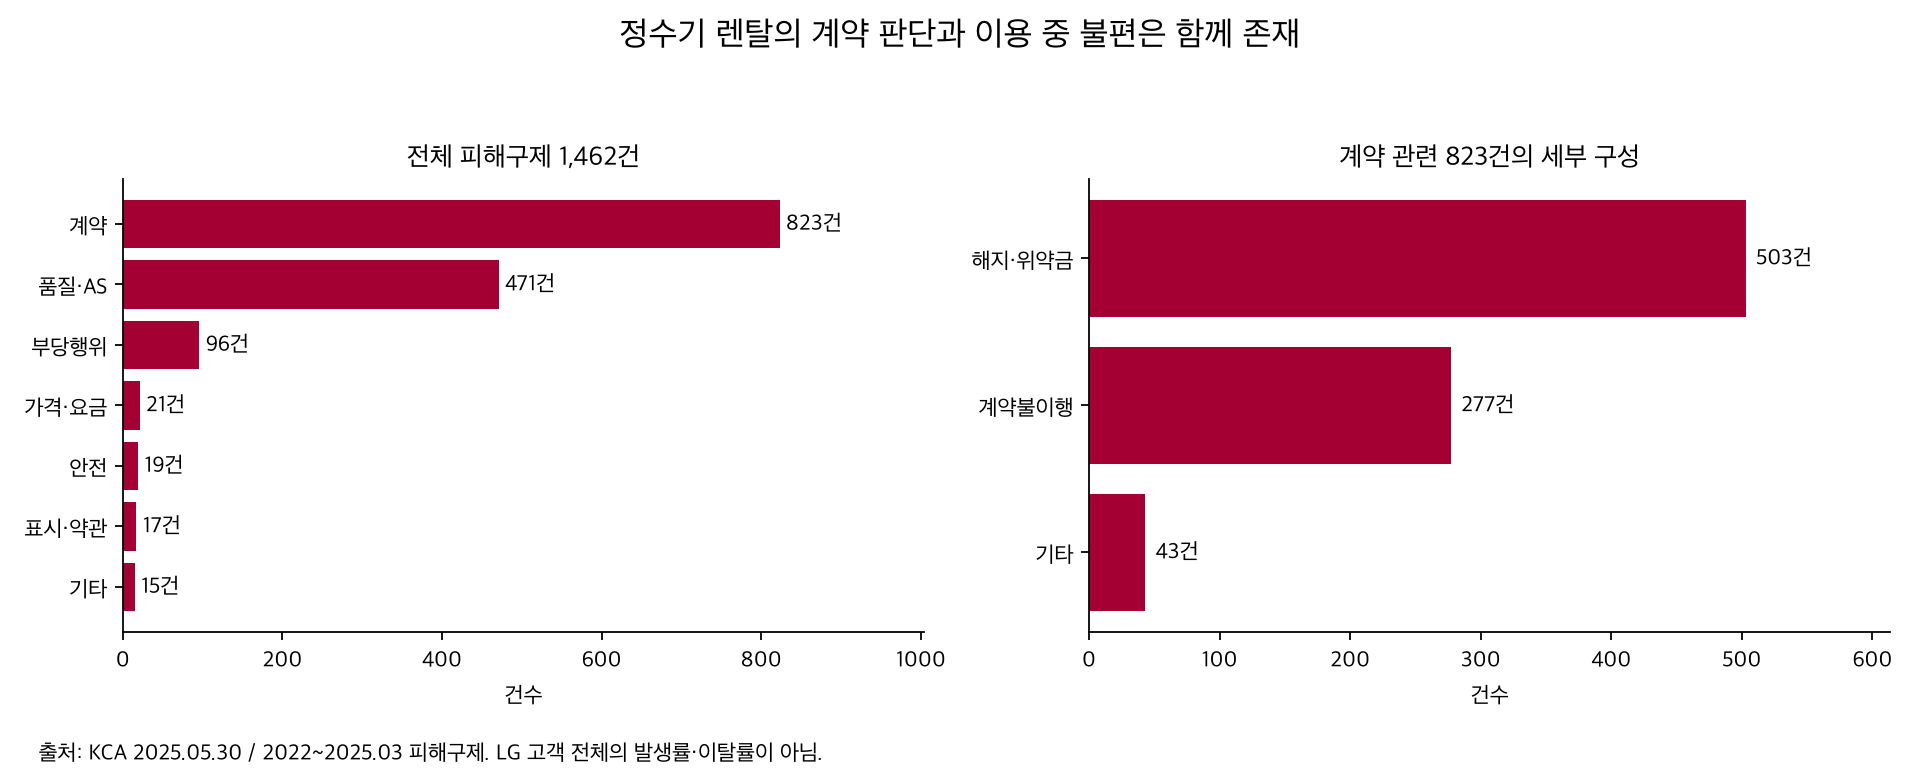

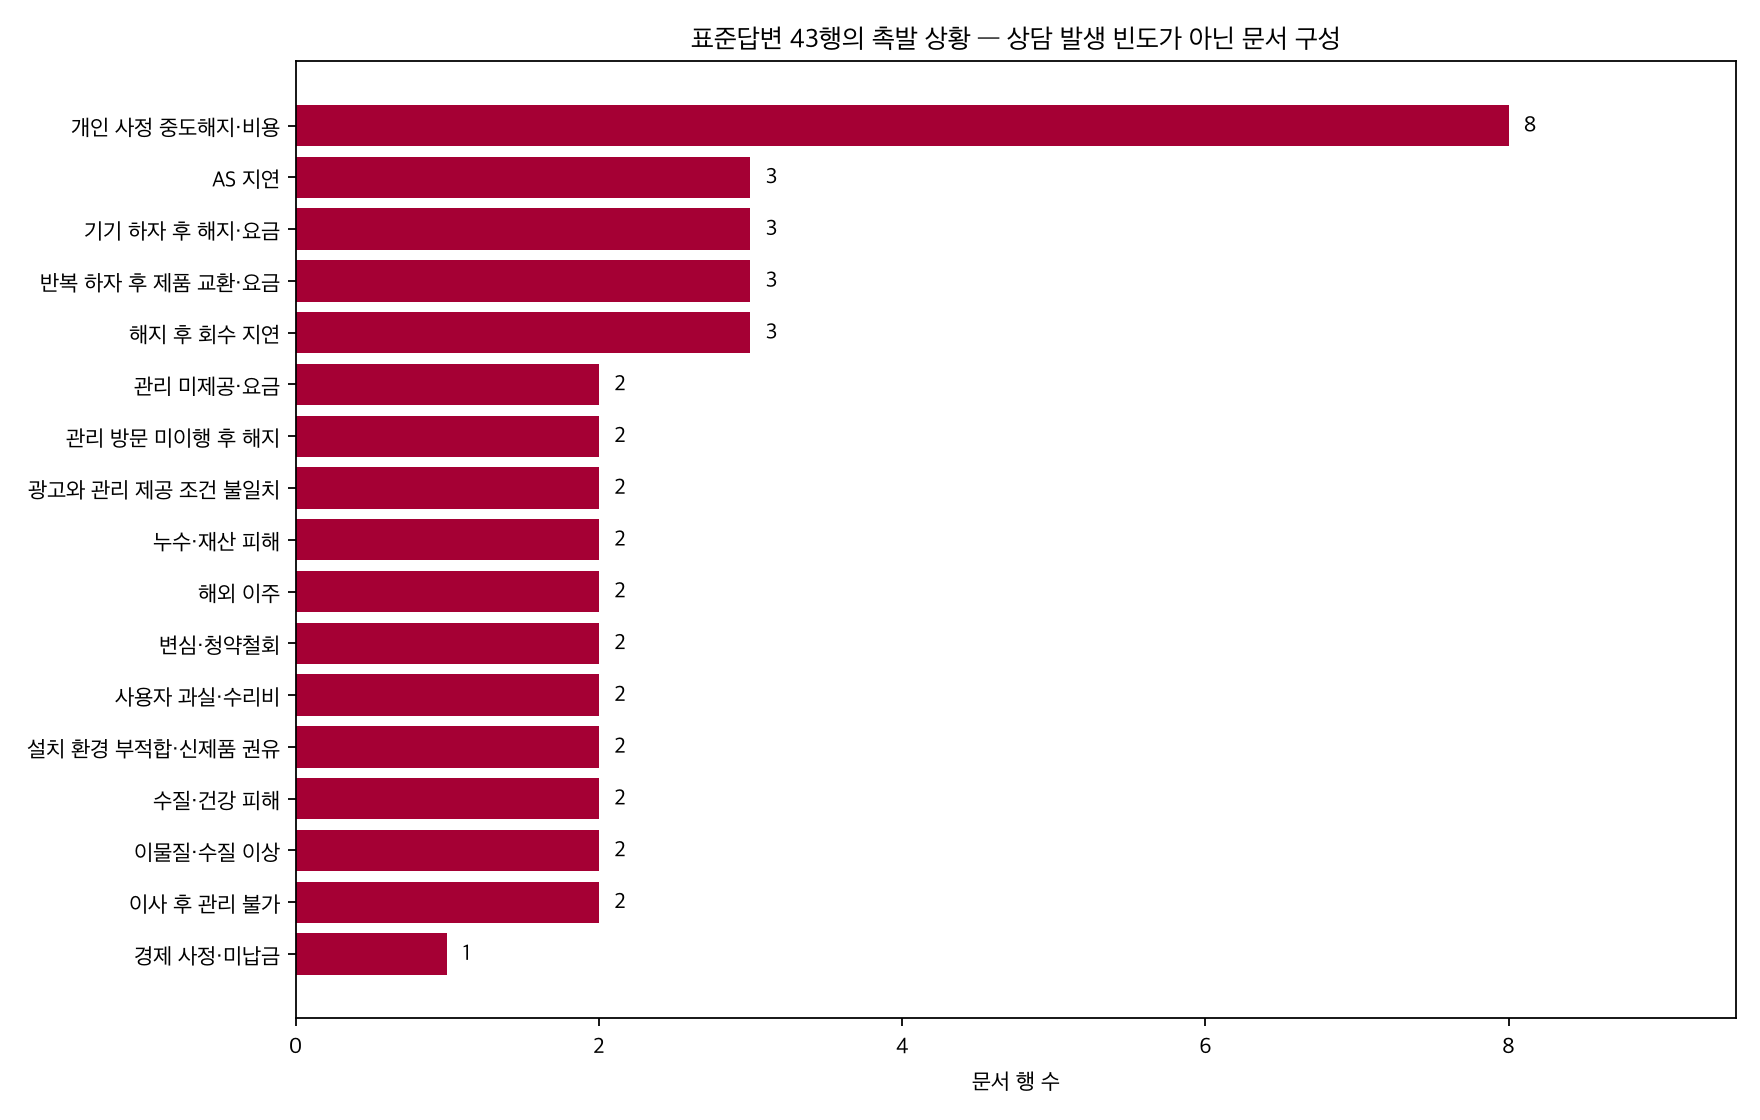

In [5]:
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib import font_manager
font=font_manager.FontProperties(fname='/System/Library/Fonts/AppleSDGothicNeo.ttc')
plt.rcParams['font.family']=font.get_name();plt.rcParams['axes.unicode_minus']=False
fig,axes=plt.subplots(1,2,figsize=(12,4.8))
for ax,frame,labelcol,title in [(axes[0],reasons,'사유','전체 피해구제 1,462건'),(axes[1],contract,'계약세부','계약 관련 823건의 세부 구성')]:
    ax.barh(frame[labelcol][::-1],frame['건수'][::-1],color='#a50034')
    for i,n in enumerate(frame['건수'][::-1]):ax.text(n+8,i,f'{n:,}건',va='center',fontsize=10)
    ax.set_xlim(0,frame['건수'].max()*1.22);ax.set_title(title);ax.set_xlabel('건수');ax.spines[['top','right']].set_visible(False)
fig.suptitle('정수기 렌탈의 계약 판단과 이용 중 불편은 함께 존재',fontsize=15)
fig.text(.02,.01,'출처: KCA 2025.05.30 / 2022~2025.03 피해구제. LG 고객 전체의 발생률·이탈률이 아님.',fontsize=10)
fig.tight_layout(rect=[0,.045,1,.93]);fig.savefig(GRAPH/'그래프_피해구제_분모구분.png',dpi=160);plt.close(fig)
display(Image(filename=str(GRAPH/'그래프_피해구제_분모구분.png')))
fig,ax=plt.subplots(figsize=(11,7));counts=summary['문서행수'].sort_values()
ax.barh(counts.index,counts.values,color='#a50034')
for i,n in enumerate(counts.values):ax.text(n+.1,i,str(n),va='center')
ax.set_xlim(0,counts.max()+1.5);ax.set_title('표준답변 43행의 촉발 상황 — 상담 발생 빈도가 아닌 문서 구성');ax.set_xlabel('문서 행 수')
fig.tight_layout();fig.savefig(GRAPH/'그래프_질문_촉발상황.png',dpi=160);plt.close(fig)
display(Image(filename=str(GRAPH/'그래프_질문_촉발상황.png')))

## 5. 선정 인사이트와 방향

확인된 연결: 관리·AS·품질 불편과 해지·요금 판단이 함께 나타나는 질문이 있고, 제품 교체 시 신규 계약 체결 가능성을 확인하라는 소비자원 안내가 있다. 따라서 핵심은 고객의 다음 선택에 필요한 근거와 계약 조건을 정리하는 것이다.

**CX 문제 가설:** 정수기 구독 고객은 관리 불편이나 제품 교체를 검토하는 상황에서, 해결 가능한 유지 대안과 기존 계약의 정산·신규 계약 조건을 함께 확인하기 어려워 다음 행동을 판단하는 데 불편을 겪는다.

대표 페르소나 이서연은 상황 설명용 가상 설정이다. 35세·맞벌이·자녀·소득의 대표성은 확인되지 않았다. 신규 구매 고객은 보조 사용자군이다.

핵심: 상황·의도 확인 → 검수 자료의 유지 대안/상담 준비 → 명확한 전환 요청 시 계약·제품·비용 비교 → 미확인 조건과 다음 행동 정리. 위험 증상·분쟁·명확한 해지 요청을 신규 구독 설득으로 우회하지 않는다.

LG 이탈 예방·재구독 전환은 사업적 기대 효과이며 실측 성과가 아니다. 유지율 또는 전환율을 만들지 않는다. 사용자 과제에서 이해도·누락·준비시간과 선택 근거를 확인한다. 기능 수가 아니라 핵심 판단 과제 완성도와 같은 시나리오의 개선 전후를 평가한다.

## 현재 대표 고객과 서비스 해석
사용·관리 불편 후 계속 사용·교체·해지 중 다음 행동을 고민하는 기존 구독 관리 담당자를 대표로 둔다. 구체 불편 해결과 고객의 명확한 선택을 존중하며, 해지 조건 안내는 실제 해지 실행과 구분한다. 위 계산값은 변경하지 않았다. 공개 사례는 불편·계약 판단 연결 근거이며 고객 부담의 크기·Agent 효과·LG 유지율은 별도 검증 대상이다.

## 현재 서비스 범위
정수기 구독 고객은 유지·교체·해지를 고민하는 상황에서, 자신의 계약기간·종료 비용과 새 구독 조건을 함께 확인하기 어려워 다음 행동을 판단하는 데 불편을 겪는다.
계약 조회·정산·새 모델 재구독 비교·상담 준비에 집중한다. 사용방법·오류는 공식 AI Chat 연결. 기존 통계 결과는 변경하지 않으며 재구독 효과를 입증한 통계로 해석하지 않는다.